# Практика 4: авто-тестирование стационарности и подбор порядка дифференцирования

**Цель:** автоматизировать проверку стационарности и обоснованно выбрать порядок дифференцирования $d$ (и сезонный $D$) на синтетическом ряду.

**Данные.** Формула ряда: месячный ряд с трендом, сезонностью периода $s=12$ и растущей дисперсией. Строим его генератором из ЛР 1:

1. `generate_time_series(trend="fast_up", seasonality="one")` даёт $100 + 150\,t/(n-1) + 10\sin(2\pi i/12) + \varepsilon_i$, $\varepsilon_i\sim N(0,3^2)$. В ЛР 1 период `one` равен 12 точкам, это ровно 12 месяцев;
2. добавляем стохастический тренд (случайное блуждание $w_t=\sum_{j\le t}\eta_j$, $\eta_j\sim N(0,0{,}03^2)$), потому что без него тренд детерминированный и «правильный» способ борьбы с ним не разность, а вычитание тренда;
3. переходим в уровни: $y_t=\exp\!\big((g_t)/60 + w_t\big)$. Сезонность и шум становятся мультипликативными, а дисперсия растёт вместе с уровнем (это нужно для шага Box–Cox).

Итого $n = 240$ месяцев (20 лет).

## 0. Импорт и генератор из ЛР 1

In [ ]:
import os
from datetime import datetime, date, time, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 100

# ---- генератор из ЛР 1 (без сохранения в файлы) ----
STEP = timedelta(minutes=5)
VARIANCE_MODES = ("const", "grow", "decay")
TREND_MODES = ("none", "fast_up", "slow_up", "fast_down", "slow_down")
EXTRA_TREND_MODES = ("exp", "poly", "log")
SEASONALITY_MODES = ("none", "one", "two")
PERIOD_1H = 12
PERIOD_6H = 72
TREND_DELTA = {"fast_up": 150.0, "slow_up": 30.0, "fast_down": -150.0, "slow_down": -30.0}


def make_timestamps(n_points, start=None):
    if start is None:
        start = datetime.combine(date.today(), time.min)
    return [start + i * STEP for i in range(n_points)]


def make_variance(mode, n_points):
    t = np.linspace(0.0, 1.0, n_points)
    if mode == "const":
        return np.ones(n_points)
    if mode == "grow":
        return 0.5 + 4.5 * t
    if mode == "decay":
        return 5.0 - 4.5 * t
    raise ValueError(f"Неизвестный режим дисперсии: {mode}")


def make_trend(mode, n_points):
    t = np.linspace(0.0, 1.0, n_points)
    if mode == "none":
        return np.zeros(n_points)
    if mode in TREND_DELTA:
        return TREND_DELTA[mode] * t
    if mode == "exp":
        return 100.0 * (np.exp(3.0 * t) - 1.0) / (np.exp(3.0) - 1.0)
    if mode == "poly":
        return 100.0 * (t ** 3 - 1.5 * t ** 2 + t)
    if mode == "log":
        return 100.0 * np.log1p(20.0 * t) / np.log1p(20.0)
    raise ValueError(f"Неизвестный режим тренда: {mode}")


def make_seasonality(mode, n_points):
    i = np.arange(n_points)
    if mode == "none":
        return np.zeros(n_points)
    if mode == "one":
        return 10.0 * np.sin(2 * np.pi * i / PERIOD_1H)
    if mode == "two":
        return (10.0 * np.sin(2 * np.pi * i / PERIOD_1H)
                + 20.0 * np.sin(2 * np.pi * i / PERIOD_6H))
    raise ValueError(f"Неизвестный режим сезонности: {mode}")


def generate_time_series(n_points=1000, variance="random", trend="random",
                         seasonality="random", base=100.0, noise_std=1.0, seed=None,
                         outliers=0, missing=0.0, start=None):
    rng = np.random.default_rng(seed)
    if variance == "random":
        variance = str(rng.choice(VARIANCE_MODES))
    if trend == "random":
        trend = str(rng.choice(TREND_MODES))
    if seasonality == "random":
        seasonality = str(rng.choice(SEASONALITY_MODES))

    timestamps = make_timestamps(n_points, start)
    noise = rng.normal(0.0, noise_std, n_points) * make_variance(variance, n_points)
    values = base + make_trend(trend, n_points) + make_seasonality(seasonality, n_points) + noise

    outlier_idx = []
    if outliers > 0:
        outlier_idx = rng.choice(n_points, size=min(outliers, n_points), replace=False)
        scale = np.std(values) * 3
        values[outlier_idx] += rng.choice([-1, 1], size=len(outlier_idx)) * scale
        outlier_idx = sorted(int(k) for k in outlier_idx)

    missing_idx = []
    if missing > 0:
        k = int(round(n_points * missing))
        missing_idx = rng.choice(n_points, size=k, replace=False)
        values[missing_idx] = np.nan
        missing_idx = sorted(int(k) for k in missing_idx)

    params = {"n_points": n_points, "step_minutes": 5,
              "start": timestamps[0].strftime("%Y-%m-%d %H:%M:%S"),
              "variance": variance, "trend": trend, "seasonality": seasonality,
              "base": base, "noise_std": noise_std, "seed": seed,
              "outliers": outlier_idx, "missing_count": len(missing_idx)}
    return timestamps, values, params

In [ ]:
%pip install arch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 13.4 MB/s  0:00:00


In [ ]:
import warnings

try:
    from statsmodels.tsa.stattools import adfuller, kpss, acf
    from statsmodels.tsa.seasonal import seasonal_decompose
except ImportError as e:
    raise ImportError("Нужен statsmodels. Выполните:  %pip install -U statsmodels") from e
try:
    from arch.unitroot import PhillipsPerron, DFGLS
except ImportError as e:
    raise ImportError("PP и DF-GLS находятся в пакете arch. Выполните:  %pip install arch") from e
try:
    from pmdarima.arima import ndiffs, nsdiffs
    HAVE_PMD = True
except Exception as e:                      # нет пакета или он несовместим с numpy
    HAVE_PMD = False
    print("pmdarima недоступен, используются запасные реализации (шаг 5). Причина:", repr(e)[:120])
from scipy import stats

ALPHA = 0.05

pmdarima недоступен, используются запасные реализации (шаг 5). Причина: ModuleNotFoundError("No module named 'pmdarima'")


## 1. Данные

In [ ]:
N = 240
idx = pd.date_range("2006-01-01", periods=N, freq="MS")

ts, vals, params = generate_time_series(
    n_points=N, variance="const", trend="fast_up", seasonality="one",
    base=100.0, noise_std=3.0, seed=11, start=datetime(2006, 1, 1))
print(params)

g = np.asarray(vals)                                  # тренд + сезонность (период 12) + шум из генератора
rng = np.random.default_rng(11)
w = np.cumsum(rng.normal(0.0, 0.03, N))               # стохастический тренд (случайное блуждание)
y = pd.Series(np.exp(g / 60.0 + w), index=idx, name="y")
print(f"y_min = {y.min():.1f}, y_max = {y.max():.1f}, n = {len(y)}, частота: {y.index.freqstr}")

{'n_points': 240, 'step_minutes': 5, 'start': '2006-01-01 00:00:00', 'variance': 'const', 'trend': 'fast_up', 'seasonality': 'one', 'base': 100.0, 'noise_std': 3.0, 'seed': 11, 'outliers': [], 'missing_count': 0}
y_min = 4.6, y_max = 80.9, n = 240, частота: MS


## 2. Шаг 1. Визуальный анализ и ACF

ACF на лаге $k$ (формула из прошлых работ):
$$r_k = \frac{\sum_{t=k+1}^{n}(x_t-\bar x)(x_{t-k}-\bar x)}{\sum_{t=1}^{n}(x_t-\bar x)^2}, \qquad \text{граница значимости } \pm 1{,}96/\sqrt n .$$
Для стационарного ряда ACF быстро спадает до нуля. Для нестационарного (тренд, единичный корень) спадает **медленно**, часто почти линейно.

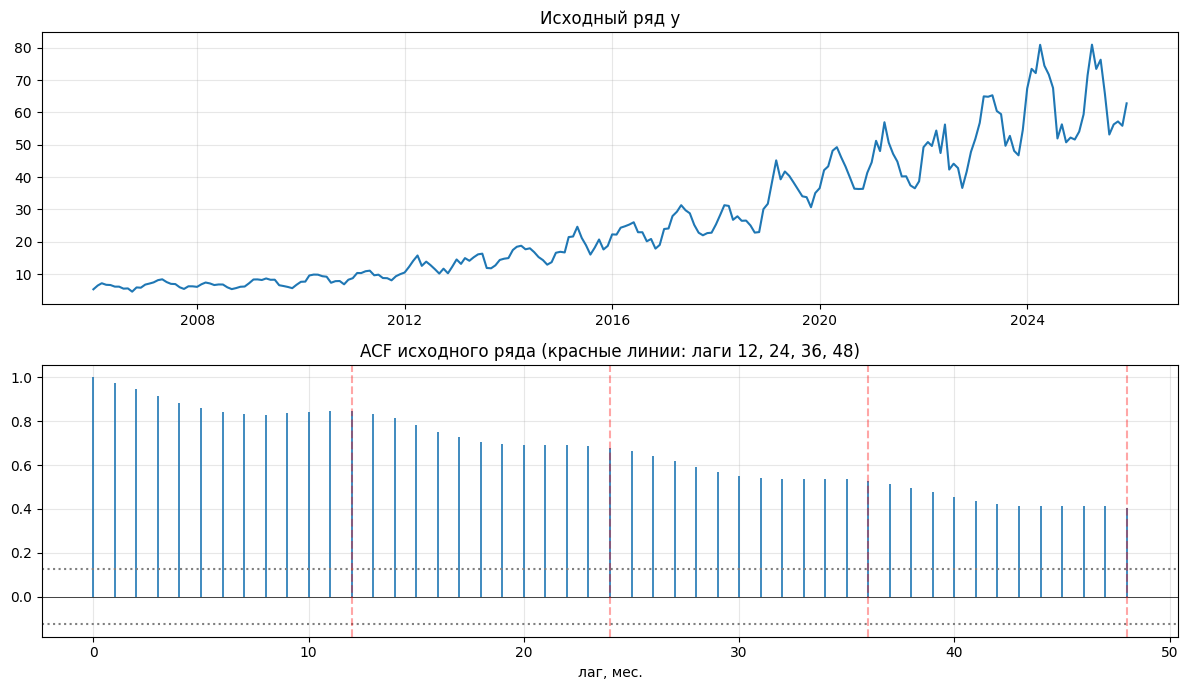

граница значимости = 1.96 / sqrt(240) = 0.1265
r_1  = 92,055 / 94,514 = 0.974
r_6  = 79,545 / 94,514 = 0.842
r_12 = 80,052 / 94,514 = 0.847
r_24 = 64,182 / 94,514 = 0.679
r_36 = 50,010 / 94,514 = 0.529


In [ ]:
def acf_manual(x, k):
    x = np.asarray(x, float); d = x - x.mean()
    num = float((d[k:] * d[:-k]).sum()); den = float((d * d).sum())
    return num, den, num / den


def plot_acf_own(ax, x, title, nlags=48):
    x = np.asarray(x, float)
    r = acf(x, nlags=nlags, fft=True)
    ax.vlines(range(len(r)), 0, r, lw=1.2)
    ax.axhline(0, color="k", lw=0.5)
    b = 1.96 / np.sqrt(len(x))
    ax.axhline(b, color="gray", ls=":"); ax.axhline(-b, color="gray", ls=":")
    for L in range(12, nlags + 1, 12):
        ax.axvline(L, color="red", ls="--", alpha=0.35)
    ax.set_title(title); ax.set_xlabel("лаг, мес."); ax.grid(alpha=0.3)


fig, axes = plt.subplots(2, 1, figsize=(12, 7))
axes[0].plot(y.index, y); axes[0].set_title("Исходный ряд y"); axes[0].grid(alpha=0.3)
plot_acf_own(axes[1], y.to_numpy(), "ACF исходного ряда (красные линии: лаги 12, 24, 36, 48)")
fig.tight_layout(); plt.show()

b = 1.96 / np.sqrt(N)
print(f"граница значимости = 1.96 / sqrt({N}) = {b:.4f}")
for L in (1, 6, 12, 24, 36):
    num, den, r = acf_manual(y.to_numpy(), L)
    print(f"r_{L:<2} = {num:,.0f} / {den:,.0f} = {r:.3f}")

## 3. Шаг 2. Тесты на исходном ряду

| тест | $H_0$ | $p<0{,}05$ означает |
|---|---|---|
| ADF | есть единичный корень | ряд стационарен |
| PP | есть единичный корень | ряд стационарен |
| DF-GLS | есть единичный корень | ряд стационарен |
| KPSS | ряд стационарен | ряд **не**стационарен |

У трёх тестов на единичный корень гипотеза о нестационарности, у KPSS наоборот, поэтому «согласованный ответ» это: p(ADF), p(PP), p(DF-GLS) < 0,05 **и** p(KPSS) ≥ 0,05 (стационарен) либо обратное (нестационарен).

Регрессия ADF: $\Delta y_t = \alpha + \gamma\,y_{t-1} + \sum_{i=1}^{p}\varphi_i\,\Delta y_{t-i}+\varepsilon_t$, $H_0:\gamma=0$ (число лагов $p$ выбирается по AIC). Столбцы `(c)` — тест с константой; `(ct)` — с константой и линейным трендом (для диагностики «тренд-стационарности», в вывод не входят).

Примечание: p-value KPSS в `statsmodels` берётся интерполяцией по таблице и ограничено диапазоном 0,01–0,10 (`InterpolationWarning`, мы его подавляем).

In [ ]:
def run_tests(x, name):
    x = pd.Series(x).dropna()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        row = {"ряд": name, "n": len(x),
               "ADF(c)": adfuller(x, regression="c", autolag="AIC")[1],
               "ADF(ct)": adfuller(x, regression="ct", autolag="AIC")[1],
               "PP(c)": PhillipsPerron(x, trend="c").pvalue,
               "DF-GLS(c)": DFGLS(x, trend="c").pvalue,
               "KPSS(c)": kpss(x, regression="c", nlags="auto")[1],
               "KPSS(ct)": kpss(x, regression="ct", nlags="auto")[1]}
    votes = [row["ADF(c)"] < ALPHA, row["PP(c)"] < ALPHA, row["DF-GLS(c)"] < ALPHA, row["KPSS(c)"] >= ALPHA]
    row["за стационарность (из 4)"] = int(sum(votes))
    row["вывод"] = ("стационарен" if sum(votes) == 4 else "нестационарен" if sum(votes) == 0 else "противоречие")
    return row


rows = []


def add_and_show(x, name):
    rows.append(run_tests(x, name))
    display(pd.DataFrame(rows).set_index("ряд").round(4))


add_and_show(y, "level")

,n,ADF(c),ADF(ct),PP(c),DF-GLS(c),KPSS(c),KPSS(ct),за стационарность (из 4),вывод
ряд,,,,,,,,,
level,240,0.9961,0.6744,0.9027,0.9918,0.01,0.01,0,нестационарен


## 4. Шаг 3. Первые разности

$\Delta y_t = y_t - y_{t-1}$ (`diff()`). Рядом показаны ряд и ACF до и после, как просит задание.

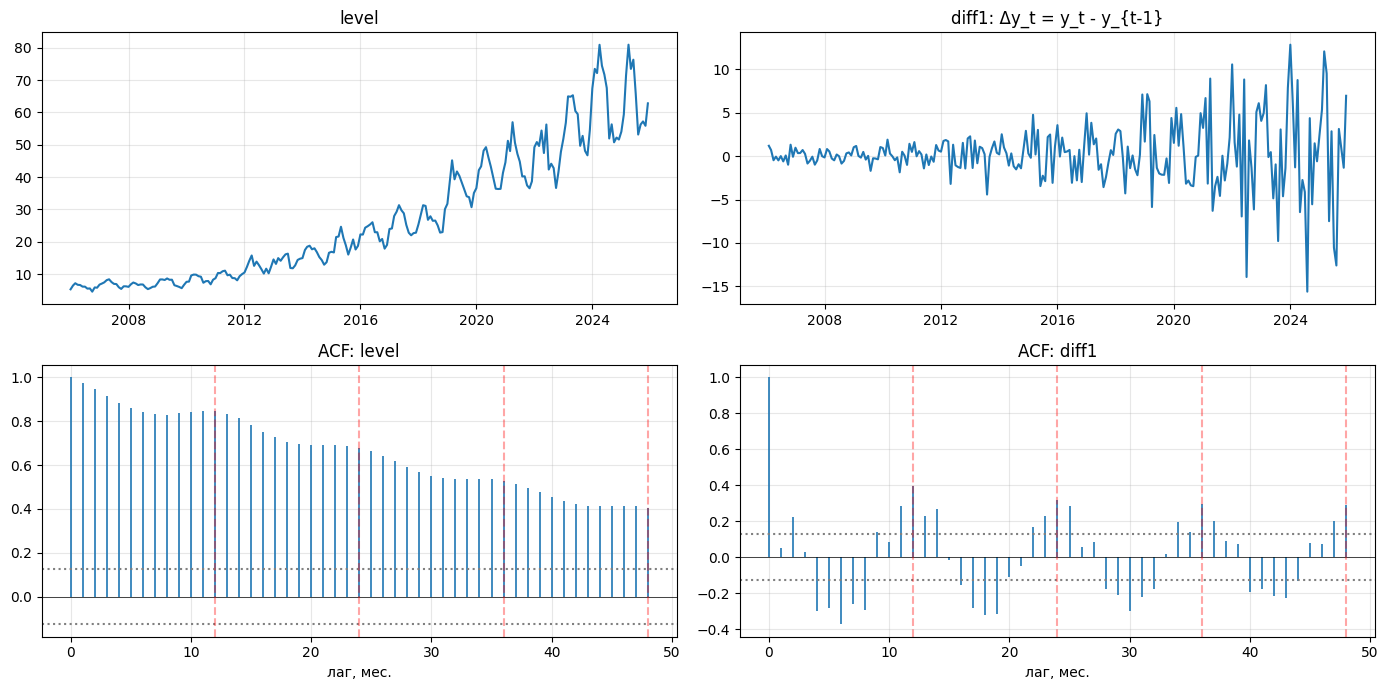

граница значимости = 1.96 / sqrt(239) = 0.1268
diff1: r_1  = 158.77 / 3,147.08 = 0.050  
diff1: r_2  = 697.19 / 3,147.08 = 0.222  (значим)
diff1: r_6  = -1,175.90 / 3,147.08 = -0.374  (значим)
diff1: r_12 = 1,244.82 / 3,147.08 = 0.396  (значим)
diff1: r_24 = 994.91 / 3,147.08 = 0.316  (значим)
diff1: r_36 = 934.03 / 3,147.08 = 0.297  (значим)


,n,ADF(c),ADF(ct),PP(c),DF-GLS(c),KPSS(c),KPSS(ct),за стационарность (из 4),вывод
ряд,,,,,,,,,
level,240,0.9961,0.6744,0.9027,0.9918,0.01,0.01,0,нестационарен
diff1,239,0.0205,0.0038,0.0000,0.2048,0.10,0.10,3,противоречие


In [ ]:
x1 = y.diff().dropna()

fig, axes = plt.subplots(2, 2, figsize=(14, 7))
axes[0, 0].plot(y.index, y); axes[0, 0].set_title("level")
axes[0, 1].plot(x1.index, x1); axes[0, 1].set_title("diff1: Δy_t = y_t - y_{t-1}")
plot_acf_own(axes[1, 0], y.to_numpy(), "ACF: level")
plot_acf_own(axes[1, 1], x1.to_numpy(), "ACF: diff1")
for ax in axes[0]:
    ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()

b1 = 1.96 / np.sqrt(len(x1))
print(f"граница значимости = 1.96 / sqrt({len(x1)}) = {b1:.4f}")
for L in (1, 2, 6, 12, 24, 36):
    num, den, r = acf_manual(x1.to_numpy(), L)
    print(f"diff1: r_{L:<2} = {num:,.2f} / {den:,.2f} = {r:.3f}  {'(значим)' if abs(r) > b1 else ''}")
add_and_show(x1, "diff1")

## 5. Шаг 4. Сезонные разности

Если после первых разностей ACF показывает значимые пики на лагах 12, 24, ..., добавляем сезонную разность $\Delta_{12}z_t = z_t - z_{t-12}$ (здесь $z=\Delta y$), то есть $(1-B)(1-B^{12})y_t$.

r_12 (diff1) = 0.396, граница = 0.1268 -> сезонная разность нужна


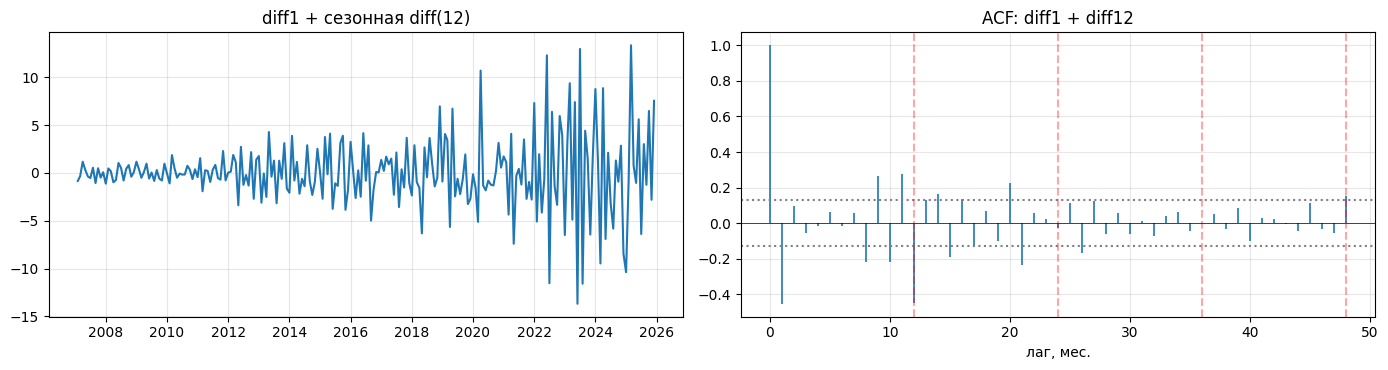

diff1+diff12: r_1  = -1,422.38 / 3,138.55 = -0.453  (граница 0.1301)
diff1+diff12: r_12 = -1,401.92 / 3,138.55 = -0.447  (граница 0.1301)
diff1+diff12: r_24 = -84.77 / 3,138.55 = -0.027  (граница 0.1301)


,n,ADF(c),ADF(ct),PP(c),DF-GLS(c),KPSS(c),KPSS(ct),за стационарность (из 4),вывод
ряд,,,,,,,,,
level,240,0.9961,0.6744,0.9027,0.9918,0.01,0.01,0,нестационарен
diff1,239,0.0205,0.0038,0.0000,0.2048,0.10,0.10,3,противоречие
diff1 + diff12,227,0.0000,0.0000,0.0000,0.0022,0.10,0.10,4,стационарен


In [ ]:
S = 12
r12 = acf_manual(x1.to_numpy(), S)[2]
need_seasonal = abs(r12) > b1
print(f"r_12 (diff1) = {r12:.3f}, граница = {b1:.4f} -> сезонная разность {'нужна' if need_seasonal else 'не нужна'}")

x_sd = x1.diff(S).dropna()           # (1 - B)(1 - B^12) y
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
axes[0].plot(x_sd.index, x_sd); axes[0].set_title("diff1 + сезонная diff(12)"); axes[0].grid(alpha=0.3)
plot_acf_own(axes[1], x_sd.to_numpy(), "ACF: diff1 + diff12")
fig.tight_layout(); plt.show()

bs = 1.96 / np.sqrt(len(x_sd))
for L in (1, 12, 24):
    num, den, r = acf_manual(x_sd.to_numpy(), L)
    print(f"diff1+diff12: r_{L:<2} = {num:,.2f} / {den:,.2f} = {r:.3f}  (граница {bs:.4f})")
add_and_show(x_sd, "diff1 + diff12")

## 6. Шаг 5. Автоматический подбор $d$ и $D$ (`pmdarima`)

`ndiffs(y, test=...)` — сколько обычных разностей нужно (тесты `kpss`, `adf`, `pp`). `nsdiffs(y, m=12, test=...)` — сколько сезонных (`ocsb`, `ch`). Если `pmdarima` не установлен, используются запасные реализации: цикл «разность, пока KPSS отвергает стационарность» для $d$ и порог силы сезонности $F_S=\max\{0,\,1-\mathrm{Var}(R)/\mathrm{Var}(S+R)\}>0{,}64$ для $D$ (критерий из `forecast::nsdiffs`).

In [ ]:
def ndiffs_fb(x, alpha=ALPHA, max_d=2):
    x = pd.Series(x).dropna(); d = 0
    while d < max_d:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            p = kpss(x, regression="c", nlags="auto")[1]
        if p >= alpha:
            break
        x = x.diff().dropna(); d += 1
    return d


def nsdiffs_fb(x, m=12, threshold=0.64):
    dec = seasonal_decompose(pd.Series(x).dropna(), model="additive", period=m)
    r = dec.resid.dropna(); s = dec.seasonal.loc[r.index]
    fs = max(0.0, 1.0 - np.var(r) / np.var(r + s))
    return int(fs > threshold)


def safe(fn, *a, **k):
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            return int(fn(*a, **k))
        # (pmdarima иногда падает на коротких или вырожденных рядах)
    except Exception as e:
        return f"ошибка: {type(e).__name__}"


ly_tmp = np.log(y)
auto = []
for name, s in (("y", y), ("log y", ly_tmp)):
    arr = s.to_numpy()
    if HAVE_PMD:
        auto.append({"ряд": name,
                     "d (kpss)": safe(ndiffs, arr, test="kpss"), "d (adf)": safe(ndiffs, arr, test="adf"),
                     "d (pp)": safe(ndiffs, arr, test="pp"),
                     "D (ocsb)": safe(nsdiffs, arr, m=12, test="ocsb"), "D (ch)": safe(nsdiffs, arr, m=12, test="ch")})
    else:
        auto.append({"ряд": name, "d (запасной kpss)": safe(ndiffs_fb, arr), "D (запасной, F_S)": safe(nsdiffs_fb, arr)})
auto_df = pd.DataFrame(auto).set_index("ряд")
display(auto_df)

# ручной вывод для сравнения: первая разность, после которой все 4 теста согласованно говорят "стационарен"
manual = pd.DataFrame(rows).set_index("ряд")
d_manual = 0 if manual.loc["level", "вывод"] == "стационарен" else (1 if manual.loc["diff1", "вывод"] == "стационарен" else 2)
D_manual = int(need_seasonal)
print(f"Ручной вывод по шагам 2-4: d = {d_manual} (по таблице тестов), D = {D_manual} (по ACF: |r_12| = {abs(r12):.3f} vs граница {b1:.4f})")

,d (запасной kpss),"D (запасной, F_S)"
ряд,,
y,1,0
log y,1,1


Ручной вывод по шагам 2-4: d = 2 (по таблице тестов), D = 1 (по ACF: |r_12| = 0.396 vs граница 0.1268)


## 7. Шаг 6. Box–Cox

Если дисперсия растёт вместе с уровнем, ряд преобразуют:
$$y^{(\lambda)}_t=\begin{cases}\dfrac{y_t^{\lambda}-1}{\lambda}, & \lambda\neq 0\\[2mm] \ln y_t, & \lambda=0\end{cases}$$
Параметр $\lambda$ ищем методом Герреро: делим ряд на годовые блоки и выбираем $\lambda$, при котором отношение $s_k/m_k^{\,1-\lambda}$ (СКО блока к степени его среднего) наиболее постоянно, то есть минимален коэффициент вариации. Если дисперсия пропорциональна квадрату уровня ($s_k\propto m_k$), получаем $\lambda=0$, то есть логарифм. (Обычный MLE из `scipy` для трендового ряда смещён: он максимизирует нормальность распределения значений, а не стабильность дисперсии.)

блоков (лет) = 20; Герреро: λ = -0.06, CV(λ) = 0.1383; CV(λ=1, без преобразования) = 0.8565
наклон log(s_k) от log(m_k): b = 1.061 -> λ ≈ 1 - b = -0.061


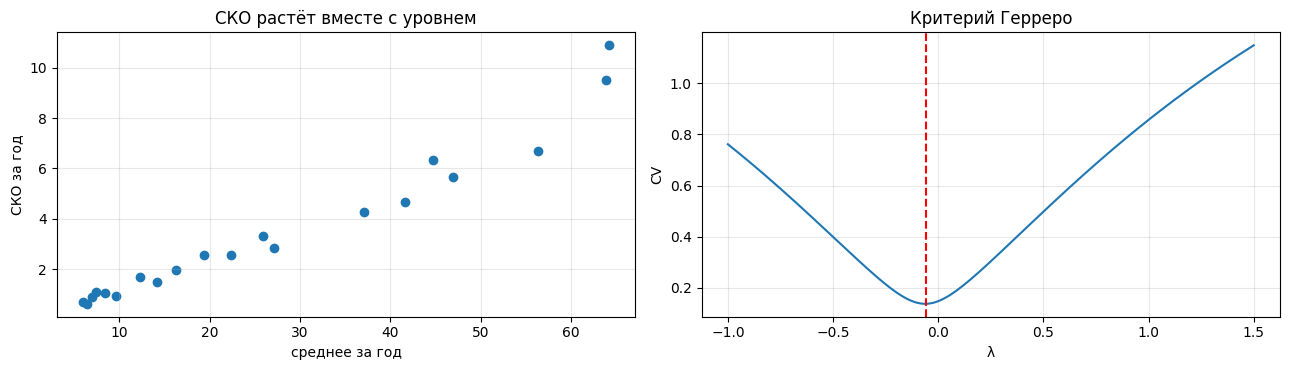

используем λ = 0.0 -> ln y


In [ ]:
blocks = y.groupby(y.index.year)
m_k = blocks.mean().to_numpy(); s_k = blocks.std().to_numpy()


def guerrero_cv(lam):
    ratio = s_k / m_k ** (1.0 - lam)
    return ratio.std(ddof=1) / ratio.mean()


grid = np.linspace(-1.0, 1.5, 251)
cv = np.array([guerrero_cv(l) for l in grid])
lam_hat = float(grid[cv.argmin()])
print(f"блоков (лет) = {len(m_k)}; Герреро: λ = {lam_hat:.2f}, CV(λ) = {cv.min():.4f}; CV(λ=1, без преобразования) = {guerrero_cv(1.0):.4f}")

# связь СКО блока и уровня: log s = a + b log m, тогда λ ≈ 1 - b
b_slope = np.polyfit(np.log(m_k), np.log(s_k), 1)[0]
print(f"наклон log(s_k) от log(m_k): b = {b_slope:.3f} -> λ ≈ 1 - b = {1 - b_slope:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].scatter(m_k, s_k); axes[0].set_xlabel("среднее за год"); axes[0].set_ylabel("СКО за год")
axes[0].set_title("СКО растёт вместе с уровнем"); axes[0].grid(alpha=0.3)
axes[1].plot(grid, cv); axes[1].axvline(lam_hat, color="r", ls="--"); axes[1].set_xlabel("λ"); axes[1].set_ylabel("CV")
axes[1].set_title("Критерий Герреро"); axes[1].grid(alpha=0.3)
fig.tight_layout(); plt.show()

lam_used = 0.0 if abs(lam_hat) < 0.2 else round(lam_hat, 1)      # около нуля -> логарифм
ly = np.log(y) if lam_used == 0.0 else (y ** lam_used - 1.0) / lam_used
ly.name = "ly"
print("используем λ =", lam_used, "->", "ln y" if lam_used == 0.0 else "степенное преобразование")

,n,ADF(c),ADF(ct),PP(c),DF-GLS(c),KPSS(c),KPSS(ct),за стационарность (из 4),вывод
ряд,,,,,,,,,
level,240,0.9961,0.6744,0.9027,0.9918,0.01,0.0100,0,нестационарен
diff1,239,0.0205,0.0038,0.0000,0.2048,0.10,0.1000,3,противоречие
diff1 + diff12,227,0.0000,0.0000,0.0000,0.0022,0.10,0.1000,4,стационарен
boxcox/log: level,240,0.9273,0.0845,0.7869,0.9813,0.01,0.0186,0,нестационарен


,n,ADF(c),ADF(ct),PP(c),DF-GLS(c),KPSS(c),KPSS(ct),за стационарность (из 4),вывод
ряд,,,,,,,,,
level,240,0.9961,0.6744,0.9027,0.9918,0.01,0.0100,0,нестационарен
diff1,239,0.0205,0.0038,0.0000,0.2048,0.10,0.1000,3,противоречие
diff1 + diff12,227,0.0000,0.0000,0.0000,0.0022,0.10,0.1000,4,стационарен
boxcox/log: level,240,0.9273,0.0845,0.7869,0.9813,0.01,0.0186,0,нестационарен
boxcox/log: diff1,239,0.0028,0.0165,0.0000,0.6226,0.10,0.1000,3,противоречие


,n,ADF(c),ADF(ct),PP(c),DF-GLS(c),KPSS(c),KPSS(ct),за стационарность (из 4),вывод
ряд,,,,,,,,,
level,240,0.9961,0.6744,0.9027,0.9918,0.0100,0.0100,0,нестационарен
diff1,239,0.0205,0.0038,0.0000,0.2048,0.1000,0.1000,3,противоречие
diff1 + diff12,227,0.0000,0.0000,0.0000,0.0022,0.1000,0.1000,4,стационарен
boxcox/log: level,240,0.9273,0.0845,0.7869,0.9813,0.0100,0.0186,0,нестационарен
boxcox/log: diff1,239,0.0028,0.0165,0.0000,0.6226,0.1000,0.1000,3,противоречие
boxcox/log: diff1 + diff12,227,0.0000,0.0000,0.0000,0.6024,0.0417,0.0100,2,противоречие


Δy     : СКО первых 60 мес. = 0.729, последних 60 мес. = 6.404, отношение = 6.404 / 0.729 = 8.78
Δ ln y : СКО первых 60 мес. = 0.106, последних 60 мес. = 0.115, отношение = 0.115 / 0.106 = 1.09


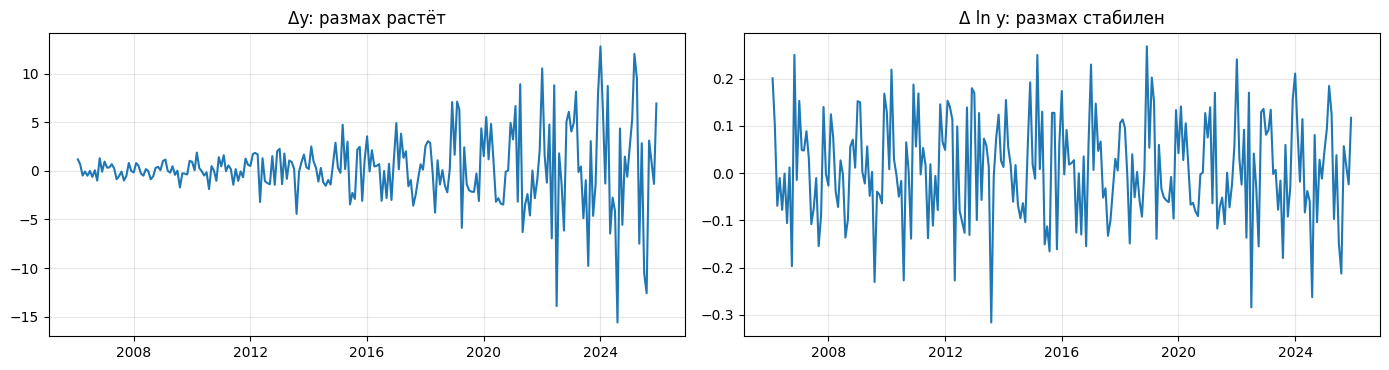

In [ ]:
# повторяем всю цепочку на преобразованном ряду
l1 = ly.diff().dropna()
l12 = l1.diff(S).dropna()
add_and_show(ly, "boxcox/log: level")
add_and_show(l1, "boxcox/log: diff1")
add_and_show(l12, "boxcox/log: diff1 + diff12")

# проверка: стабилизировалась ли дисперсия разностей (первая и последняя пятилетки)
h = 60
for name, s in (("Δy", y.diff().dropna()), ("Δ ln y", l1)):
    a, z = s.iloc[:h].std(), s.iloc[-h:].std()
    print(f"{name:7s}: СКО первых {h} мес. = {a:.3f}, последних {h} мес. = {z:.3f}, отношение = {z:.3f} / {a:.3f} = {z / a:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
axes[0].plot(y.diff().dropna()); axes[0].set_title("Δy: размах растёт")
axes[1].plot(l1); axes[1].set_title("Δ ln y: размах стабилен")
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()

## 8. Сводная таблица p-values

In [ ]:
final = pd.DataFrame(rows).set_index("ряд")
display(final.round(4))

,n,ADF(c),ADF(ct),PP(c),DF-GLS(c),KPSS(c),KPSS(ct),за стационарность (из 4),вывод
ряд,,,,,,,,,
level,240,0.9961,0.6744,0.9027,0.9918,0.0100,0.0100,0,нестационарен
diff1,239,0.0205,0.0038,0.0000,0.2048,0.1000,0.1000,3,противоречие
diff1 + diff12,227,0.0000,0.0000,0.0000,0.0022,0.1000,0.1000,4,стационарен
boxcox/log: level,240,0.9273,0.0845,0.7869,0.9813,0.0100,0.0186,0,нестационарен
boxcox/log: diff1,239,0.0028,0.0165,0.0000,0.6226,0.1000,0.1000,3,противоречие
boxcox/log: diff1 + diff12,227,0.0000,0.0000,0.0000,0.6024,0.0417,0.0100,2,противоречие


## 9. Шаг 7. Вывод

## Итоговое преобразование

**ln y → первая разность (d = 1) → сезонная разность лага 12 (D = 1)**, то есть

$$z_t = (1-B)(1-B^{12})\ln y_t, \qquad \text{SARIMA}(p,1,q)(P,1,Q)_{12}.$$

## Обоснование по шагам

### 1. Исходный ряд нестационарен

- ACF спадает медленно: r₁ = 0,974; r₁₂ = 0,847; r₂₄ = 0,679; r₃₆ = 0,529 (граница значимости ±0,1265). На лагах 12, 24, 36 видна сезонная «ступенька».
- Все 4 теста согласованы (0 из 4 за стационарность): ADF p = 0,996, PP p = 0,903, DF-GLS p = 0,992 не отвергают единичный корень; KPSS p ≤ 0,01 отвергает стационарность.
- ADF с трендом (ct) тоже не отвергает единичный корень (p = 0,674), значит тренд стохастический, а не только детерминированный. Поэтому нужна разность, а не вычитание тренда.

### 2. Логарифм (Box–Cox, λ ≈ 0): стабилизация дисперсии

- СКО по годам растёт вместе со средним уровнем. Наклон log(sₖ) по log(mₖ) равен b = 1,061, откуда λ ≈ 1 − b = −0,061.
- Метод Герреро даёт λ = −0,06; коэффициент вариации падает с 0,857 (без преобразования) до 0,138. λ близко к нулю, берём λ = 0, то есть ln y.
- Проверка: отношение СКО последних 60 и первых 60 месяцев для Δy равно 8,78 (размах растёт почти в 9 раз), для Δ ln y равно 1,09 (дисперсия стабильна).
- Сам логарифм нестационарность не убирает: у ln y тесты по-прежнему 0 из 4 (ADF 0,927; PP 0,787; DF-GLS 0,981; KPSS 0,01).

### 3. Первая разность (d = 1): убирает единичный корень

| ряд | ADF | PP | DF-GLS | KPSS | за стационарность |
|---|---|---|---|---|---|
| Δy | 0,0205 | 0,0000 | 0,2048 | ≥ 0,10 | 3 из 4 |
| Δ ln y | 0,0028 | 0,0000 | 0,6226 | ≥ 0,10 | 3 из 4 |

ADF и PP отвергают единичный корень, KPSS не отвергает стационарность, то есть три теста согласованы. Вторая разность не нужна (d = 2 избыточно).

### 4. Сезонная разность лага 12 (D = 1): убирает сезонность

- После Δ ACF сезонных лагов остаётся значимой: r₁₂ = 0,396; r₂₄ = 0,316; r₃₆ = 0,297 (граница 0,127), а r₆ = −0,374 (типично для периода 12). При этом r₁ = 0,050 незначим, то есть остаточная структура именно сезонная.
- После Δ₁₂ сезонные пики исчезают (r₂₄ = −0,027). Для y все 4 теста согласованы (ADF = PP = 0,0000; DF-GLS = 0,0022; KPSS ≥ 0,10).

## Где тесты согласованы и где возникли противоречия

**Согласованный ответ (4 из 4 или 0 из 4):**
- исходный ряд y и ln y: нестационарны (0 из 4);
- y после Δ + Δ₁₂: стационарен (4 из 4).

**Противоречия и их причины:**

| случай | что произошло | вероятная причина |
|---|---|---|
| Δy и Δ ln y (3 из 4) | DF-GLS не отвергает единичный корень (p = 0,205 и 0,623) | У DF-GLS низкая мощность при остаточной сезонной структуре; остальные три теста однозначны |
| Δ₁₂Δ ln y (2 из 4) | ADF и PP: p < 0,0001, DF-GLS: 0,602, KPSS(c): 0,042 (на границе), KPSS(ct): 0,01 | Передифференцирование: r₁ = −0,453 и r₁₂ = −0,447 (сильные отрицательные автокорреляции, MA-корень близок к 1). Это искажает оценку долгосрочной дисперсии в KPSS и снижает мощность DF-GLS. Реальной нестационарности здесь нет |
| ADF/PP против KPSS в целом | Тесты проверяют противоположные гипотезы | Разная реакция на детерминированный тренд, автокорреляцию остатков; p-value KPSS ограничено диапазоном 0,01–0,10 |

Сезонность в данных детерминированная (синус из генератора), поэтому Δ₁₂ усиливает шум и добавляет MA-член. Более экономная альтернатива: ln y + Δ + сезонные индикаторы (дамми по месяцам) вместо Δ₁₂.

## Авто-подбор против ручного выбора

В запуске использовались запасные реализации (колонки «запасной»), а не `pmdarima`.

| ряд | d (KPSS) | D (критерий F_S) |
|---|---|---|
| y | 1 | 0 |
| ln y | 1 | 1 |

- **d**: совпадает с ручным выбором (d = 1) на обоих рядах.
- **D**: на сыром y автоподбор даёт D = 0, на ln y даёт D = 1. Расхождение объясняется тем, что критерий F_S опирается на аддитивное разложение: на сыром ряду с растущим размахом остаток раздут, и сила сезонности занижается. После логарифма сезонность становится аддитивной, и критерий согласуется с ACF (D = 1).

## Итог

Преобразование **ln y → Δ → Δ₁₂** обосновано так: логарифм стабилизирует дисперсию (отношение СКО 8,78 → 1,09), первая разность убирает единичный корень (ADF, PP, KPSS согласованы), сезонная разность убирает сезонные пики ACF (r₁₂ = 0,396 → r₂₄ = −0,027). Оставшиеся противоречия тестов объясняются мощностью DF-GLS и эффектом передифференцирования, а не нестационарностью ряда.
